### **Importing the dependencies**

In [1]:
import os
import json
import random
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from PIL import Image

import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.preprocessing.image import ImageDataGenerator

from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay


random.seed(42)
np.random.seed(42)
tf.random.set_seed(42)

print("TensorFlow:", tf.__version__)
print("Available GPUs:", tf.config.list_physical_devices("GPU"))

import pandas as pd

TensorFlow: 2.21.0
Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


### **Data Curation**

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import os
import shutil

PROJECT_DIR = (
    "/content/drive/MyDrive/Colab Notebooks/ML_Projects/"
    "Plant_Disease_Detection"
)

DRIVE_COLOR_DIR = os.path.join(
    PROJECT_DIR, "plantvillage dataset", "color"
)

LOCAL_DATASET_ROOT = "/content/plantvillage dataset"
LOCAL_COLOR_DIR = os.path.join(LOCAL_DATASET_ROOT, "color")

print("Paths defined successfully.")
print("Source:", DRIVE_COLOR_DIR)
print("Destination:", LOCAL_COLOR_DIR)

Paths defined successfully.
Source: /content/drive/MyDrive/Colab Notebooks/ML_Projects/Plant_Disease_Detection/plantvillage dataset/color
Destination: /content/plantvillage dataset/color


In [4]:
print("Source folder exists:", os.path.isdir(DRIVE_COLOR_DIR))

if os.path.isdir(DRIVE_COLOR_DIR):
    print("Number of class folders:", sum(
        os.path.isdir(os.path.join(DRIVE_COLOR_DIR, name))
        for name in os.listdir(DRIVE_COLOR_DIR)
    ))
else:
    print("Check the PROJECT_DIR path.")

Source folder exists: True
Number of class folders: 38


In [5]:
if os.path.exists(LOCAL_DATASET_ROOT):
    shutil.rmtree(LOCAL_DATASET_ROOT)

os.makedirs(LOCAL_DATASET_ROOT, exist_ok=True)

print("Local destination prepared:", LOCAL_DATASET_ROOT)

Local destination prepared: /content/plantvillage dataset


In [6]:
shutil.copytree(DRIVE_COLOR_DIR, LOCAL_COLOR_DIR)

print("Copy completed:", os.path.isdir(LOCAL_COLOR_DIR))

Copy completed: True


In [7]:
classes = [
    name for name in os.listdir(LOCAL_COLOR_DIR)
    if os.path.isdir(os.path.join(LOCAL_COLOR_DIR, name))
]

print("Dataset exists:", os.path.isdir(LOCAL_COLOR_DIR))
print("Number of class folders:", len(classes))
print("First 5 classes:", classes[:5])

Dataset exists: True
Number of class folders: 38
First 5 classes: ['Tomato___Septoria_leaf_spot', 'Pepper,_bell___healthy', 'Corn_(maize)___healthy', 'Peach___Bacterial_spot', 'Orange___Haunglongbing_(Citrus_greening)']


In [8]:
DATASET_ROOT = LOCAL_COLOR_DIR
color_dir = LOCAL_COLOR_DIR
base_dir = color_dir

print("Dataset path:", color_dir)
print("Path exists:", os.path.isdir(color_dir))

Dataset path: /content/plantvillage dataset/color
Path exists: True


In [9]:
assert os.path.isdir(color_dir), (
    f"Dataset folder not found: {color_dir}"
)

print("Dataset folder found successfully.")

Dataset folder found successfully.


In [10]:
print("Color dataset folder contents (class folders):")
print(sorted(os.listdir(color_dir))[:20])

Color dataset folder contents (class folders):
['Apple___Apple_scab', 'Apple___Black_rot', 'Apple___Cedar_apple_rust', 'Apple___healthy', 'Blueberry___healthy', 'Cherry_(including_sour)___Powdery_mildew', 'Cherry_(including_sour)___healthy', 'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot', 'Corn_(maize)___Common_rust_', 'Corn_(maize)___Northern_Leaf_Blight', 'Corn_(maize)___healthy', 'Grape___Black_rot', 'Grape___Esca_(Black_Measles)', 'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)', 'Grape___healthy', 'Orange___Haunglongbing_(Citrus_greening)', 'Peach___Bacterial_spot', 'Peach___healthy', 'Pepper,_bell___Bacterial_spot', 'Pepper,_bell___healthy']


In [11]:
print("Color dataset contents:")

class_folders = sorted([
    folder for folder in os.listdir(color_dir)
    if os.path.isdir(os.path.join(color_dir, folder))
])

print("\nNumber of plant disease classes:", len(class_folders))
print("First 5 classes:", class_folders[:5])

Color dataset contents:

Number of plant disease classes: 38
First 5 classes: ['Apple___Apple_scab', 'Apple___Black_rot', 'Apple___Cedar_apple_rust', 'Apple___healthy', 'Blueberry___healthy']


In [12]:
class_name = "Grape___healthy"
class_path = os.path.join(color_dir, class_name)

assert os.path.isdir(class_path), (
    f"Class folder not found: {class_path}"
)

images = os.listdir(class_path)

print("Number of images:", len(images))
print("First 5 images:", images[:5])

Number of images: 423
First 5 images: ['6ff46c3b-bcbe-4a9b-8286-425cb92cb2ee___Mt.N.V_HL 8947.JPG', 'dc94bb19-48ca-47d7-87ad-98cf5ec46aad___Mt.N.V_HL 6181.JPG', '1e126702-2613-4265-b2df-03648d947627___Mt.N.V_HL 9108.JPG', '4782587e-f8b6-4586-95c0-2fef6507c990___Mt.N.V_HL 6209.JPG', '304f5d6d-b17f-4e89-9196-9e649f117d03___Mt.N.V_HL 6189.JPG']


### **Exploratory data analysis (EDA)**

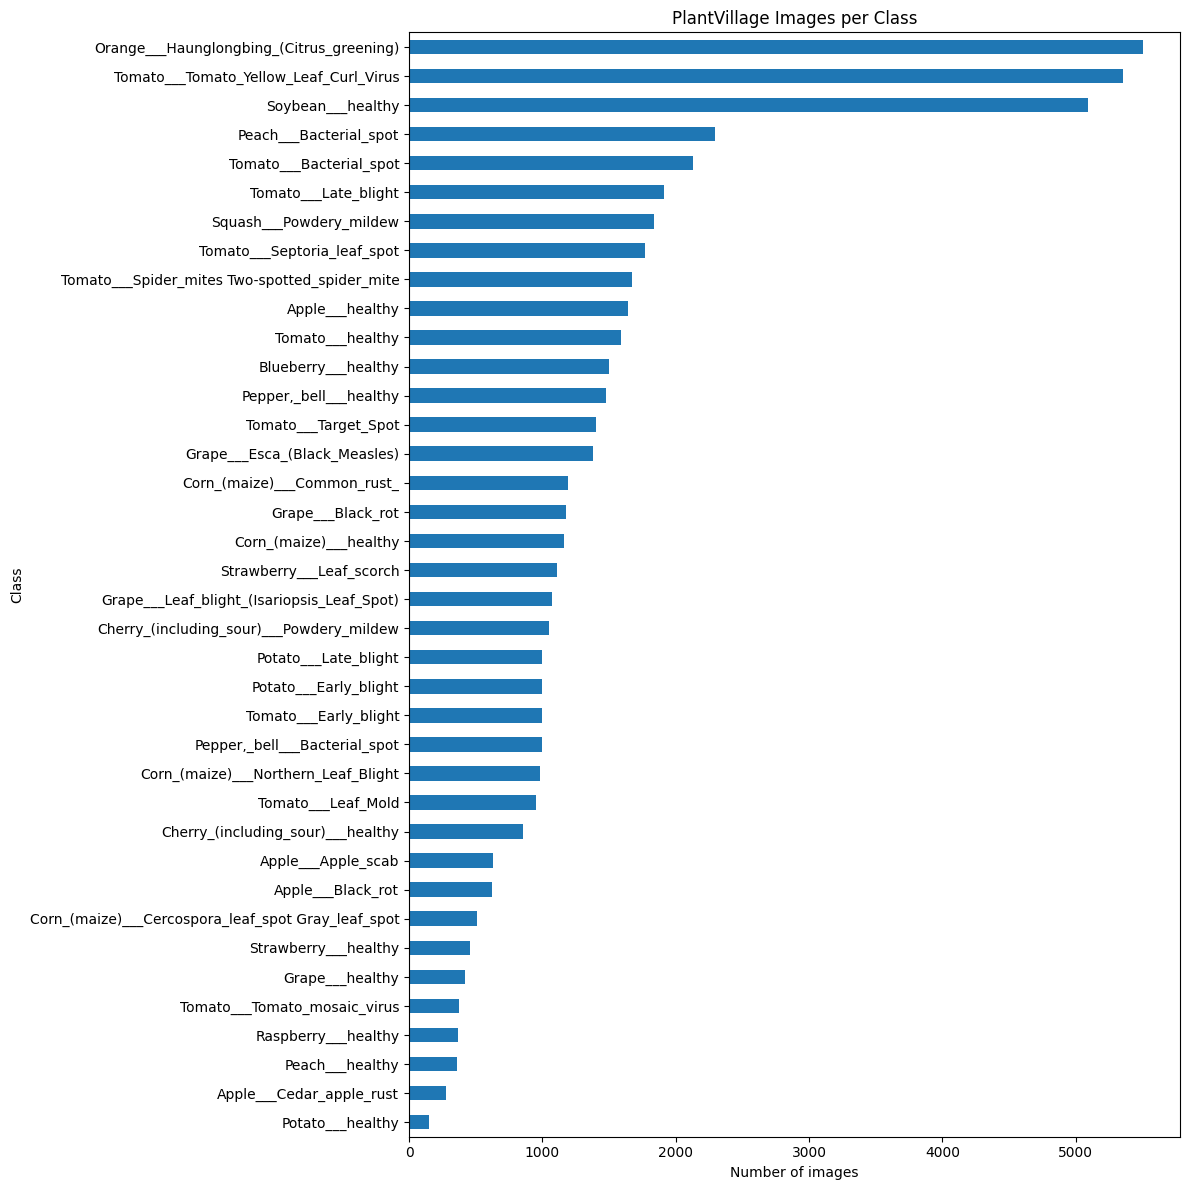

Classes: 38
Total images: 54305
Minimum images per class: 152
Maximum images per class: 5507


In [13]:
class_counts = {}
valid_extensions = (".jpg", ".jpeg", ".png", ".bmp", ".webp")

for class_folder in sorted(os.listdir(color_dir)):
    folder_path = os.path.join(color_dir, class_folder)
    if os.path.isdir(folder_path):
        class_counts[class_folder] = sum(
            1 for filename in os.listdir(folder_path)
            if filename.lower().endswith(valid_extensions)
        )

counts = pd.Series(class_counts).sort_values(ascending=False)

plt.figure(figsize=(12, 12))
counts.sort_values().plot(kind="barh")
plt.title("PlantVillage Images per Class")
plt.xlabel("Number of images")
plt.ylabel("Class")
plt.tight_layout()
plt.show()

print("Classes:", len(counts))
print("Total images:", int(counts.sum()))
print("Minimum images per class:", int(counts.min()))
print("Maximum images per class:", int(counts.max()))

In [18]:
dataset_dir = "/content/plantvillage dataset/color"

top_3_classes = [
    "Orange___Haunglongbing_(Citrus_greening)",
    "Tomato___Tomato_Yellow_Leaf_Curl_Virus",
    "Soybean___healthy"
]

target_samples = 2000

for class_name in top_3_classes:
    class_dir = os.path.join(dataset_dir, class_name)

    images = [
        f for f in os.listdir(class_dir)
        if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp"))
    ]

    if len(images) > target_samples:
        remove_images = random.sample(
            images, len(images) - target_samples
        )

        for image_name in remove_images:
            os.remove(os.path.join(class_dir, image_name))

    print(class_name, "remaining:",
          len(os.listdir(class_dir)))

Orange___Haunglongbing_(Citrus_greening) remaining: 2000
Tomato___Tomato_Yellow_Leaf_Curl_Virus remaining: 2000
Soybean___healthy remaining: 2000


#### **Sample images across disease classes**

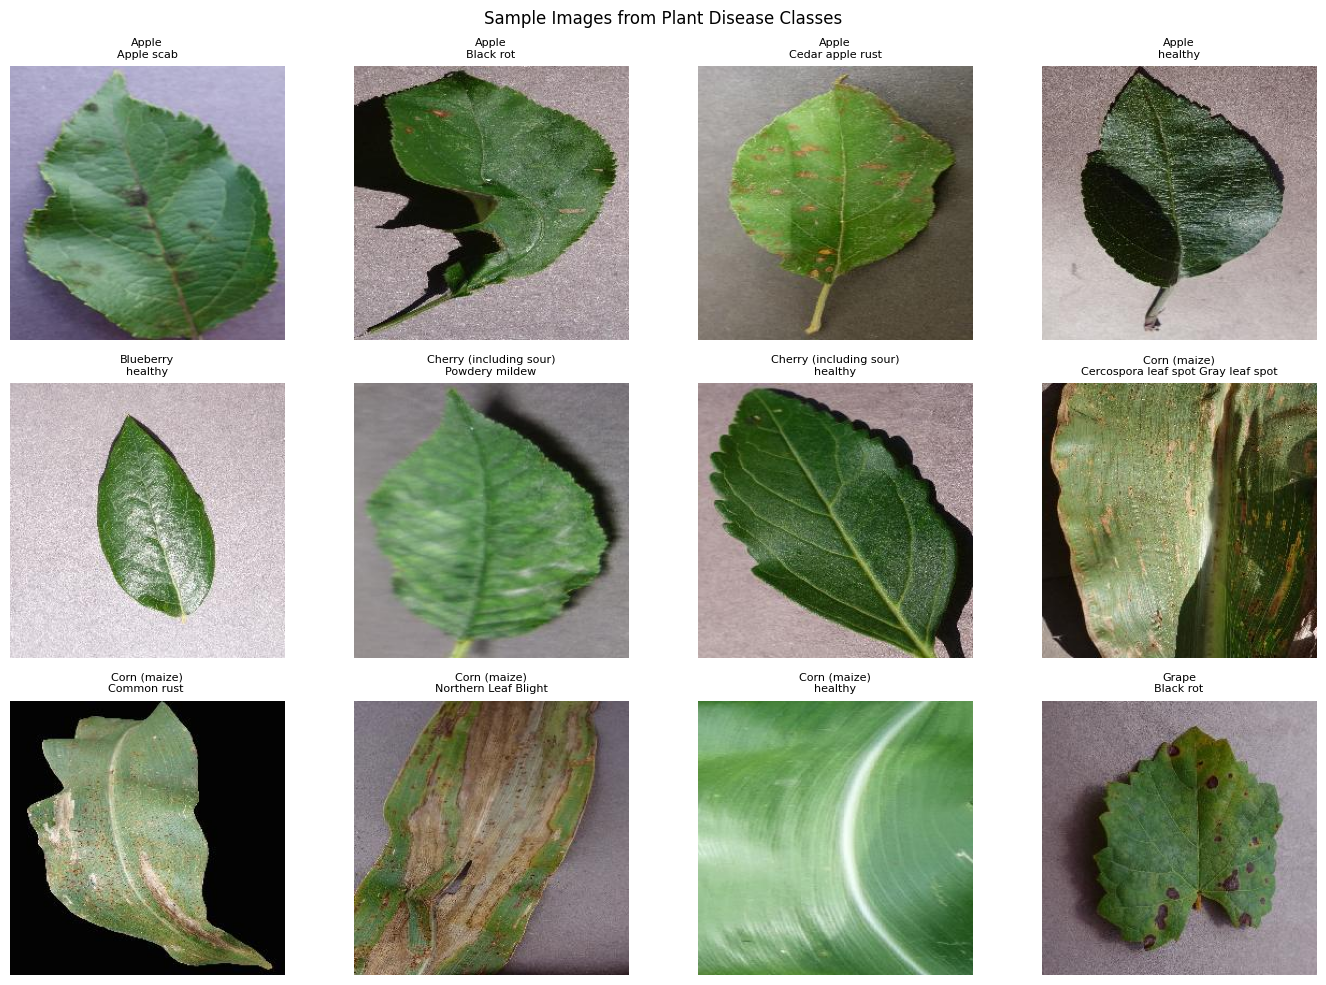

In [19]:
sample_classes = sorted([
    folder for folder in os.listdir(color_dir)
    if os.path.isdir(os.path.join(color_dir, folder))
])[:12]

fig, axes = plt.subplots(3, 4, figsize=(14, 10))
for ax, class_folder in zip(axes.flat, sample_classes):
    folder_path = os.path.join(color_dir, class_folder)
    candidates = [
        f for f in os.listdir(folder_path)
        if f.lower().endswith(valid_extensions)
    ]
    if candidates:
        sample_path = os.path.join(folder_path, sorted(candidates)[0])
        with Image.open(sample_path) as im:
            ax.imshow(im.convert("RGB"))
        ax.set_title(class_folder.replace("___", "\n").replace("_", " "), fontsize=8)
    ax.axis("off")

for ax in axes.flat[len(sample_classes):]:
    ax.axis("off")

plt.suptitle("Sample Images from Plant Disease Classes")
plt.tight_layout()
plt.show()

### **Data Preprocessing**

In [20]:
base_dir = color_dir

print("Base directory:", base_dir)
print("Exists:", os.path.isdir(base_dir))

Base directory: /content/plantvillage dataset/color
Exists: True


Image path: /content/plantvillage dataset/color/Apple___Cedar_apple_rust/54f60420-248f-41f6-be1a-a0be7936005f___FREC_C.Rust 3801.JPG
Image shape: (256, 256, 3)


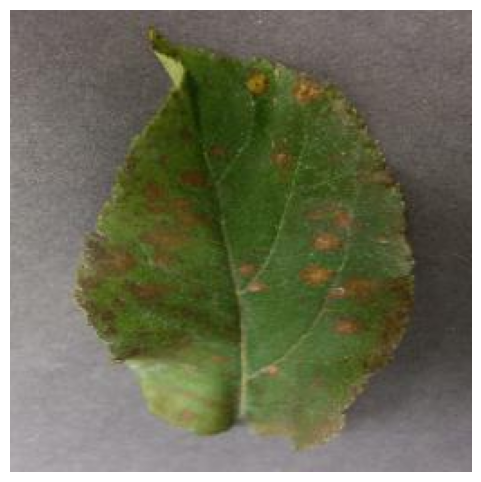

In [21]:
class_name = "Apple___Cedar_apple_rust"
class_path = os.path.join(base_dir, class_name)

image_files = [
    f for f in os.listdir(class_path)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
]

assert image_files, f"No images found in {class_path}"

image_path = os.path.join(class_path, image_files[0])

img = mpimg.imread(image_path)

print("Image path:", image_path)
print("Image shape:", img.shape)

plt.figure(figsize=(6, 6))
plt.imshow(img)
plt.axis("off")
plt.show()

Image path: /content/plantvillage dataset/color/Apple___Cedar_apple_rust/025b2b9a-0ec4-4132-96ac-7f2832d0db4a___FREC_C.Rust 3655.JPG
Image shape: (256, 256, 3)


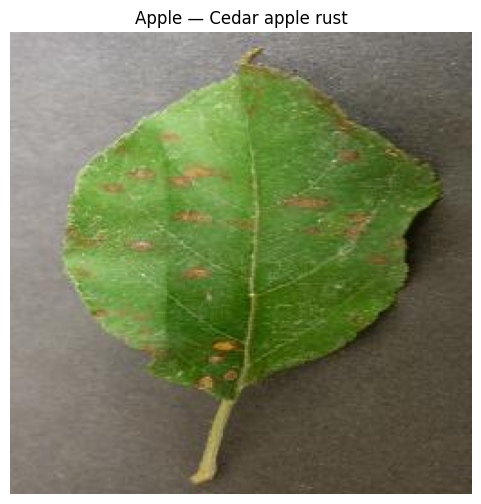

In [22]:
class_name = "Apple___Cedar_apple_rust"
class_path = os.path.join(base_dir, class_name)
image_files = sorted([
    f for f in os.listdir(class_path)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
])
assert image_files, f"No supported images found in {class_path}"

image_path = os.path.join(class_path, image_files[0])
img = mpimg.imread(image_path)

print("Image path:", image_path)
print("Image shape:", img.shape)
plt.figure(figsize=(6, 6))
plt.imshow(img)
plt.title(class_name.replace("___", " — ").replace("_", " "))
plt.axis("off")
plt.show()


In [23]:
img_size = 224
batch_size = 32
validation_split = 0.20

### **Train Test Split**

In [24]:
data_gen = ImageDataGenerator(
    rescale=1.0 / 255.0,
    validation_split=validation_split
)

In [25]:
train_generator = data_gen.flow_from_directory(
    base_dir,
    target_size=(img_size, img_size),
    batch_size=batch_size,
    subset="training",
    class_mode="categorical",
    shuffle=True,
    seed=42
)

Found 35492 images belonging to 38 classes.


In [26]:
validation_generator = data_gen.flow_from_directory(
    base_dir,
    target_size=(img_size, img_size),
    batch_size=batch_size,
    subset="validation",
    class_mode="categorical",
    shuffle=False,
    seed=42
)

class_names = list(train_generator.class_indices.keys())
num_classes = train_generator.num_classes
print("Number of classes:", num_classes)
print("Training images:", train_generator.samples)
print("Validation images:", validation_generator.samples)

Found 8859 images belonging to 38 classes.
Number of classes: 38
Training images: 35492
Validation images: 8859


### **CNN architecture**

In [27]:
model = models.Sequential([
    layers.Input(shape=(img_size, img_size, 3)),
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D(pool_size=(2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D(pool_size=(2, 2)),

    layers.Flatten(),
    layers.Dense(256, activation="relu"),
    layers.Dense(num_classes, activation="softmax")
], name="plant_disease_cnn")

In [28]:
model.summary()

trainable_params = int(np.sum([
    np.prod(weight.shape) for weight in model.trainable_weights
]))
total_params = model.count_params()
print(f"Trainable parameters: {trainable_params:,}")
print(f"Total parameters: {total_params:,}")

Model: "plant_disease_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 186624)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │    47,776,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 38)             │         9,766 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 47,805,158 (182.36 MB)

 Trainable params: 47,805,158 (182.36 MB)

 Non-trainable params: 0 (0.00 B)

Trainable parameters: 47,805,158
Total parameters: 47,805,158


#### **CNN architecture diagram**

In [ ]:
from tensorflow.keras.utils import plot_model
from IPython.display import Image as DisplayImage, display
import os
import numpy as np

architecture_path = os.path.join(MODEL_DIR if "MODEL_DIR" in globals() else "/content", "cnn_architecture.png")
plot_model(
    model,
    to_file=architecture_path,
    show_shapes=True,
    show_layer_names=True,
    show_dtype=False,
    rankdir="TB",
    expand_nested=True,
    dpi=120,
)
display(DisplayImage(filename=architecture_path))

In [30]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

In [31]:
MODEL_DIR = PROJECT_DIR
os.makedirs(MODEL_DIR, exist_ok=True)

best_model_path = os.path.join(MODEL_DIR, "plant_disease_best.keras")

checkpoint_callback = tf.keras.callbacks.ModelCheckpoint(
    filepath=best_model_path,
    monitor="val_accuracy",
    save_best_only=True,
    mode="max",
    verbose=1
)


reduce_lr_callback = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.3,
    patience=2,
    min_lr=1e-6,
    verbose=1
)

callbacks = [checkpoint_callback, reduce_lr_callback]

### **Model training**

In [32]:
history = model.fit(
    train_generator,
    epochs=6,
    validation_data=validation_generator,
    callbacks=callbacks
)

if os.path.exists(best_model_path):
    model = tf.keras.models.load_model(best_model_path)
    print("Loaded best checkpoint:", best_model_path)

Epoch 1/6
1110/1110 ━━━━━━━━━━━━━━━━━━━━ 0s 98ms/step - accuracy: 0.4884 - loss: 2.5445
Epoch 1: val_accuracy improved from None to 0.80224, saving model to /content/drive/MyDrive/Colab Notebooks/ML_Projects/Plant_Disease_Detection/plant_disease_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Colab Notebooks/ML_Projects/Plant_Disease_Detection/plant_disease_best.keras
1110/1110 ━━━━━━━━━━━━━━━━━━━━ 146s 124ms/step - accuracy: 0.6574 - loss: 1.3046 - val_accuracy: 0.8022 - val_loss: 0.6639 - learning_rate: 0.0010
Epoch 2/6
1110/1110 ━━━━━━━━━━━━━━━━━━━━ 0s 98ms/step - accuracy: 0.8643 - loss: 0.4334
Epoch 2: val_accuracy improved from 0.80224 to 0.81251, saving model to /content/drive/MyDrive/Colab Notebooks/ML_Projects/Plant_Disease_Detection/plant_disease_best.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Colab Notebooks/ML_Projects/Plant_Disease_Detection/plant_disease_best.keras
1110/1110 ━━━━━━━━━━━━━━━━━━━━ 136s 122ms/step - accuracy: 0.8655 

### **Model Evaluation**

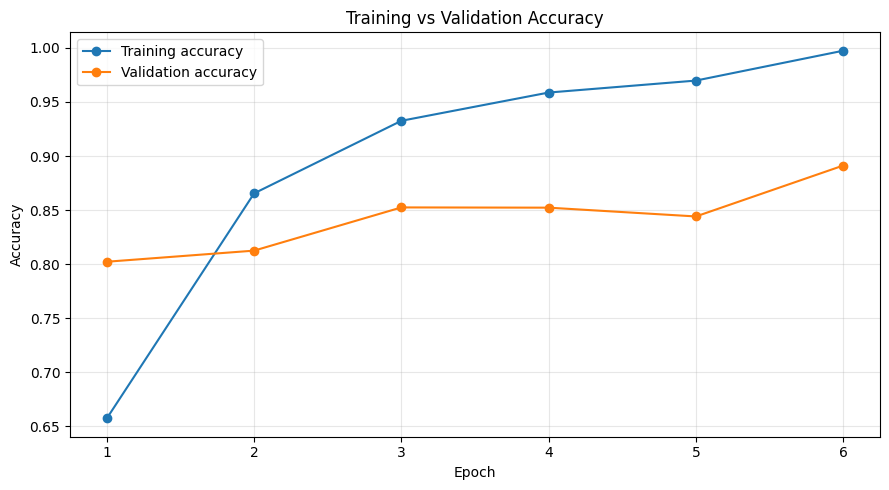

In [33]:
epochs_ran = range(1, len(history.history["accuracy"]) + 1)

plt.figure(figsize=(9, 5))
plt.plot(epochs_ran, history.history["accuracy"], marker="o", label="Training accuracy")
plt.plot(epochs_ran, history.history["val_accuracy"], marker="o", label="Validation accuracy")
plt.title("Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.xticks(list(epochs_ran))
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

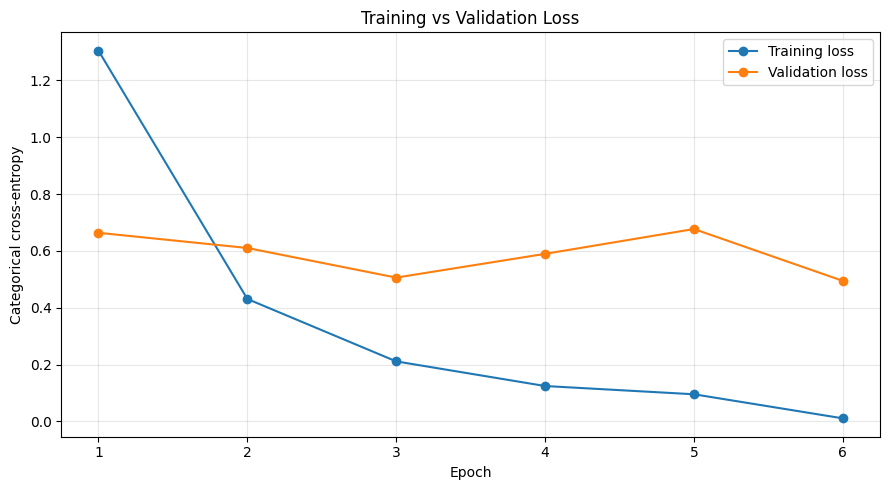

In [34]:
plt.figure(figsize=(9, 5))
plt.plot(epochs_ran, history.history["loss"], marker="o", label="Training loss")
plt.plot(epochs_ran, history.history["val_loss"], marker="o", label="Validation loss")
plt.title("Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Categorical cross-entropy")
plt.xticks(list(epochs_ran))
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [35]:
validation_generator.reset()
val_loss, val_accuracy = model.evaluate(validation_generator, verbose=1)
print(f"Validation loss: {val_loss:.4f}")
print(f"Validation accuracy: {val_accuracy * 100:.2f}%")

validation_generator.reset()
probabilities = model.predict(validation_generator, verbose=1)
y_pred = np.argmax(probabilities, axis=1)
y_true = validation_generator.classes
class_names = list(validation_generator.class_indices.keys())

print("\nClassification report:")
print(classification_report(
    y_true, y_pred,
    labels=np.arange(len(class_names)),
    target_names=class_names,
    digits=4,
    zero_division=0
))

277/277 ━━━━━━━━━━━━━━━━━━━━ 31s 108ms/step - accuracy: 0.8912 - loss: 0.4948
Validation loss: 0.4948
Validation accuracy: 89.12%
277/277 ━━━━━━━━━━━━━━━━━━━━ 23s 83ms/step

Classification report:
                                                    precision    recall  f1-score   support

                                Apple___Apple_scab     0.7967    0.7778    0.7871       126
                                 Apple___Black_rot     0.9008    0.8790    0.8898       124
                          Apple___Cedar_apple_rust     0.8302    0.8000    0.8148        55
                                   Apple___healthy     0.8825    0.8450    0.8634       329
                               Blueberry___healthy     0.9500    0.9500    0.9500       300
          Cherry_(including_sour)___Powdery_mildew     0.9479    0.9524    0.9501       210
                 Cherry_(including_sour)___healthy     0.8474    0.9471    0.8944       170
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot     0.7717    0

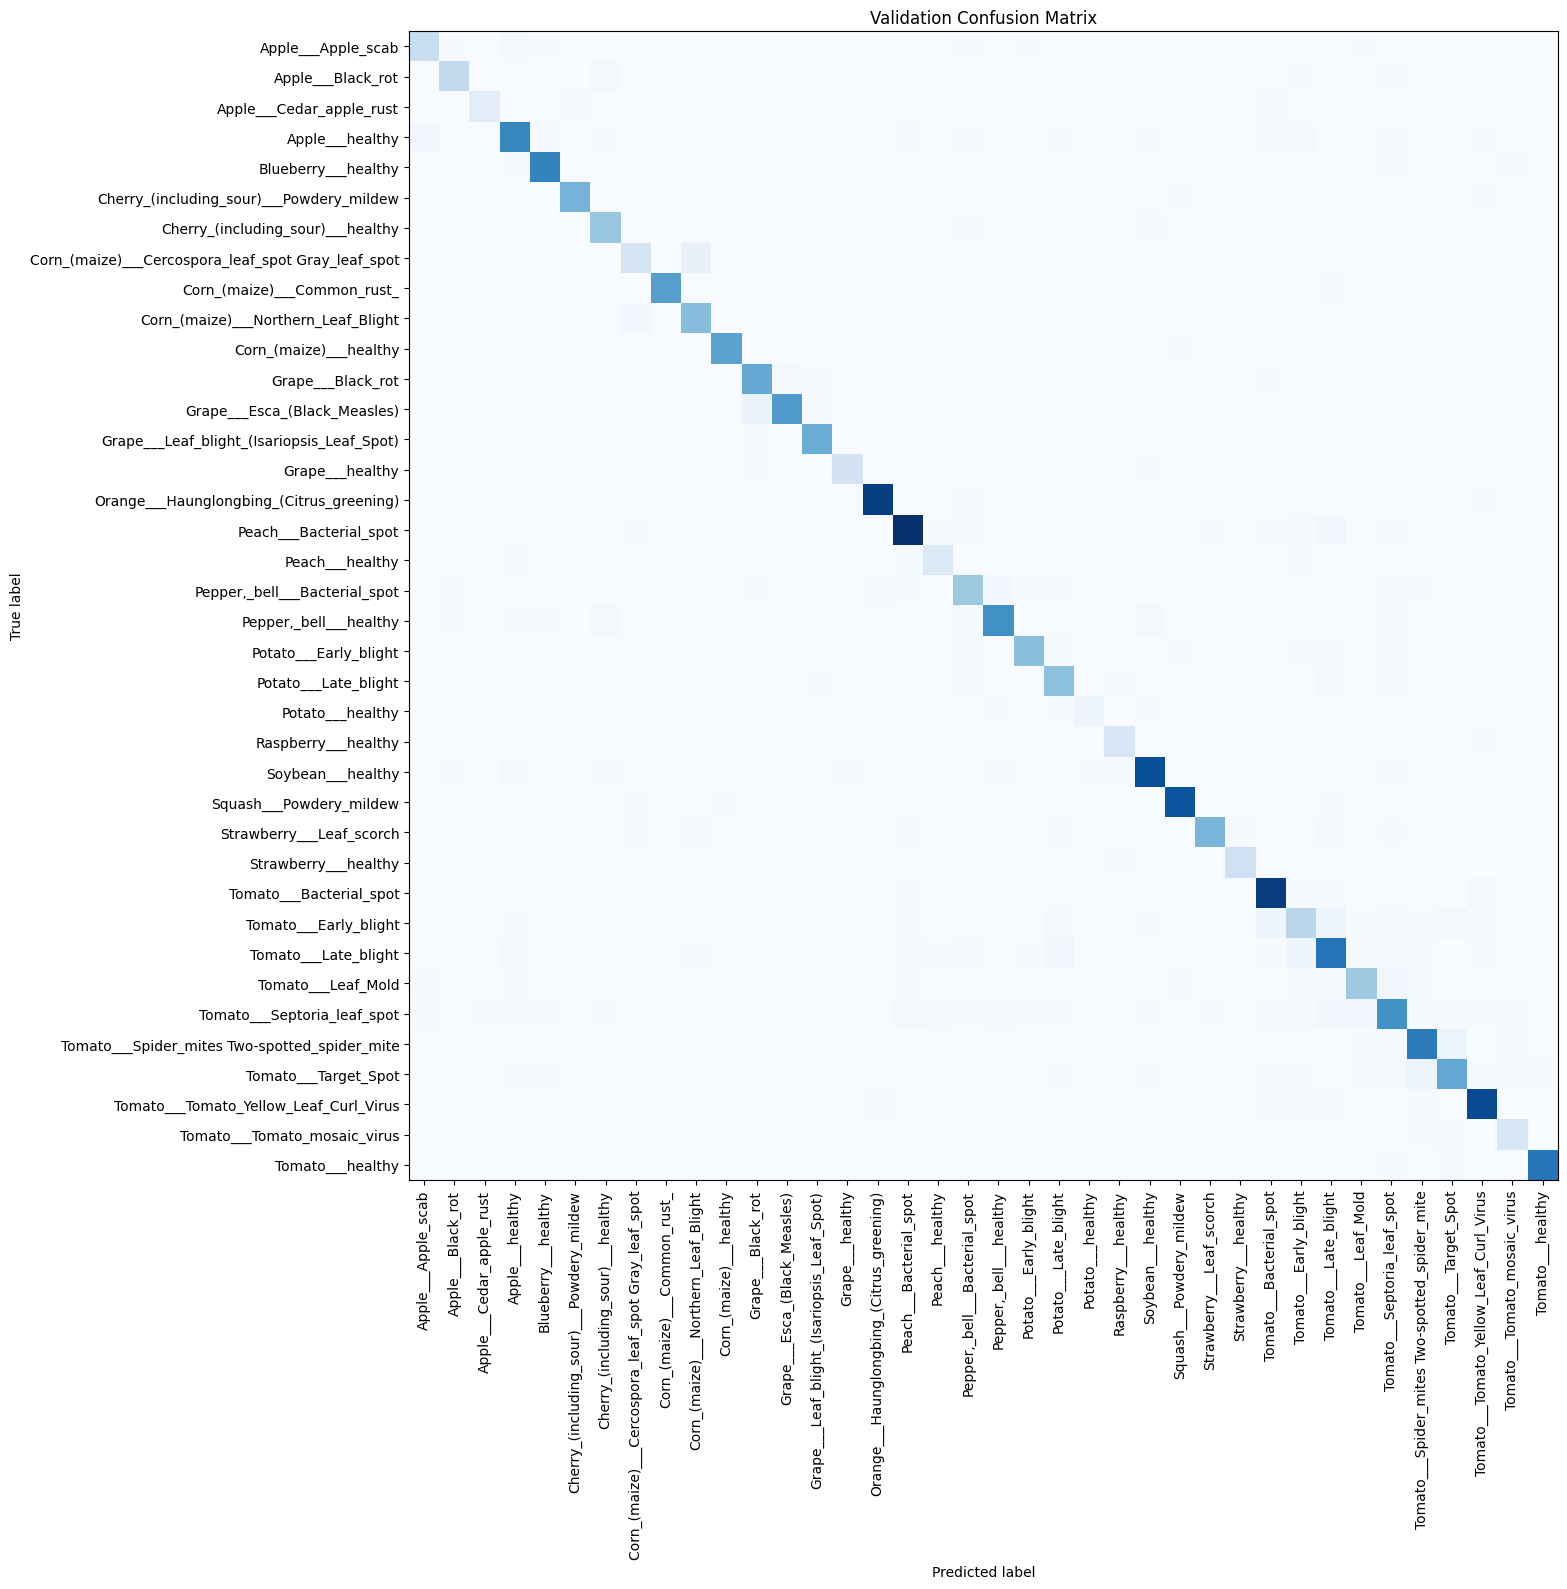

In [36]:
cm = confusion_matrix(y_true, y_pred, labels=np.arange(len(class_names)))

fig, ax = plt.subplots(figsize=(18, 16))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot(
    ax=ax,
    include_values=False,
    xticks_rotation=90,
    cmap="Blues",
    colorbar=False
)
ax.set_title("Validation Confusion Matrix")
plt.tight_layout()
plt.show()

### **Weight and bias distributions**

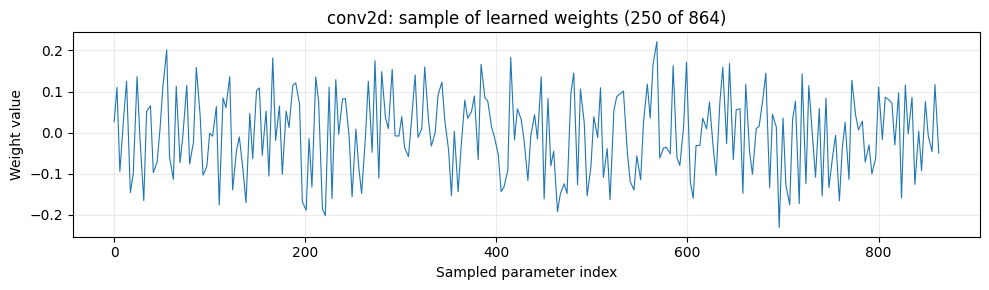

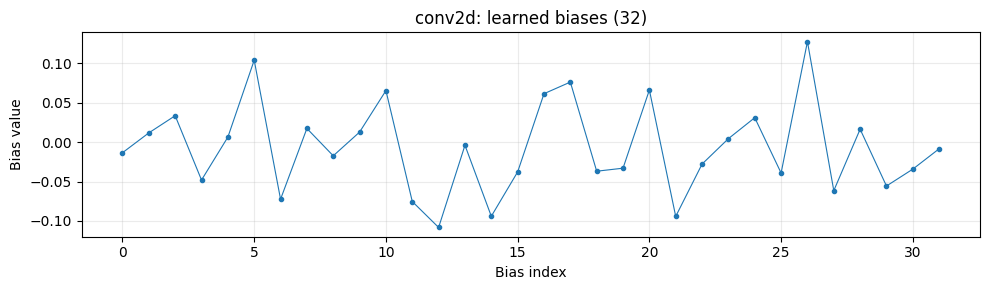

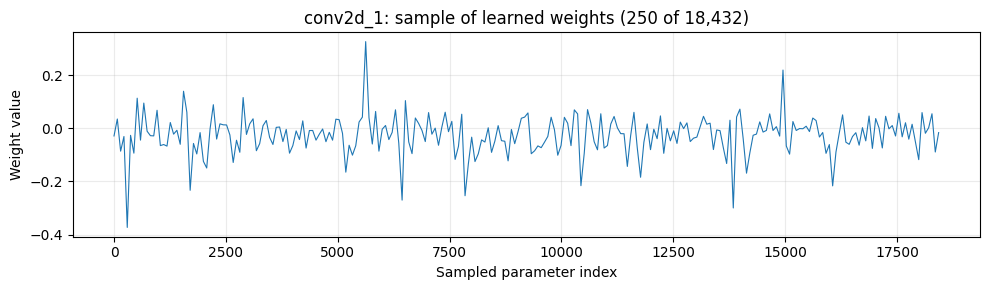

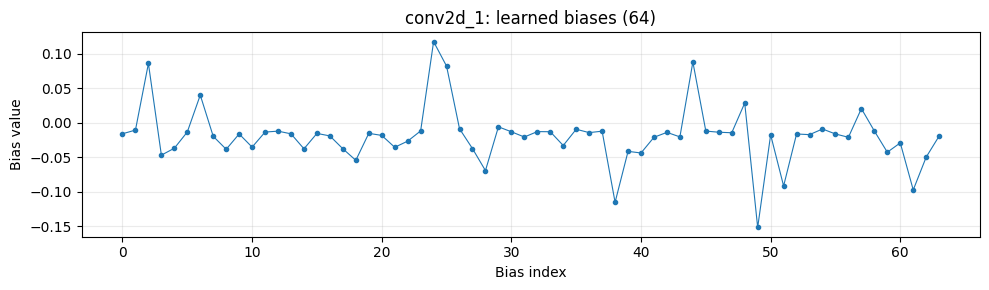

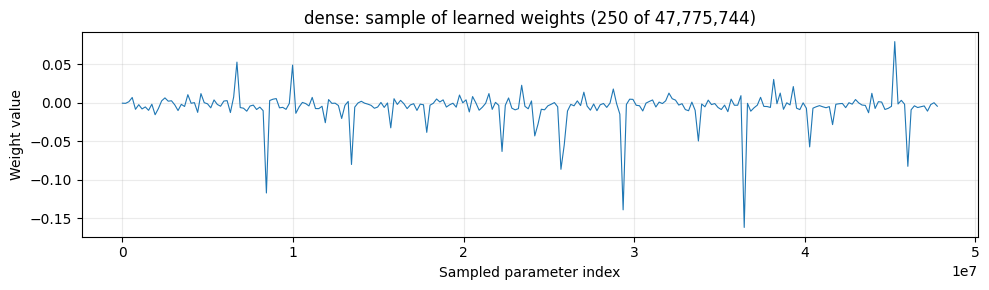

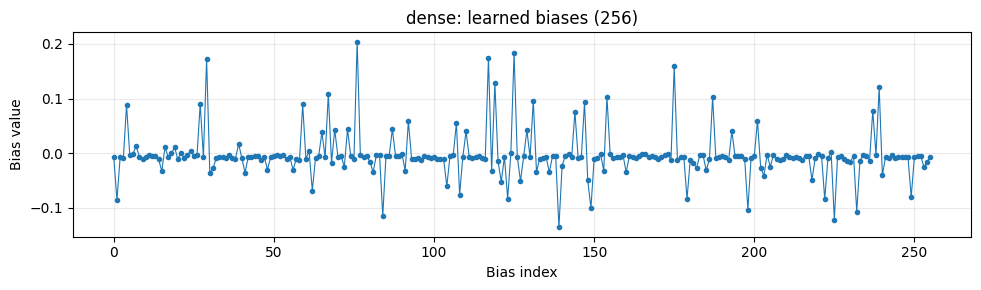

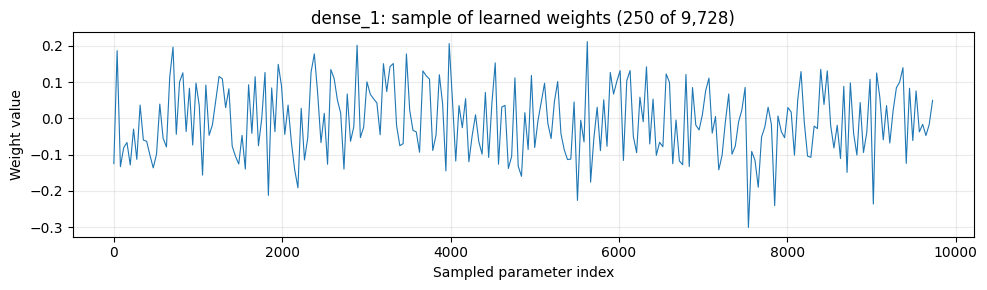

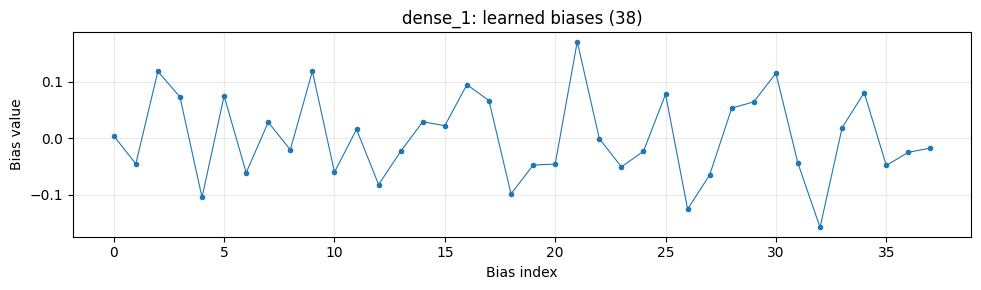

In [37]:
parameter_layers = [layer for layer in model.layers if isinstance(layer, (layers.Conv2D, layers.Dense))]
for layer in parameter_layers:
    params = layer.get_weights()
    if not params:
        continue
    weights = params[0].ravel()
    sample_n = min(250, weights.size)
    sample_idx = np.linspace(0, weights.size - 1, sample_n, dtype=int)
    plt.figure(figsize=(10, 3))
    plt.plot(sample_idx, weights[sample_idx], linewidth=0.8)
    plt.title(f"{layer.name}: sample of learned weights ({sample_n} of {weights.size:,})")
    plt.xlabel("Sampled parameter index")
    plt.ylabel("Weight value")
    plt.grid(True, alpha=0.25)
    plt.tight_layout()
    plt.show()

    if len(params) > 1:
        biases = params[1].ravel()
        plt.figure(figsize=(10, 3))
        plt.plot(np.arange(biases.size), biases, marker=".", linewidth=0.8)
        plt.title(f"{layer.name}: learned biases ({biases.size:,})")
        plt.xlabel("Bias index")
        plt.ylabel("Bias value")
        plt.grid(True, alpha=0.25)
        plt.tight_layout()
        plt.show()
    else:
        print(f"{layer.name}: no separate bias vector (bias may be disabled).")

Filter tensor shape: (3, 3, 3, 32)
Bias vector shape: (32,)


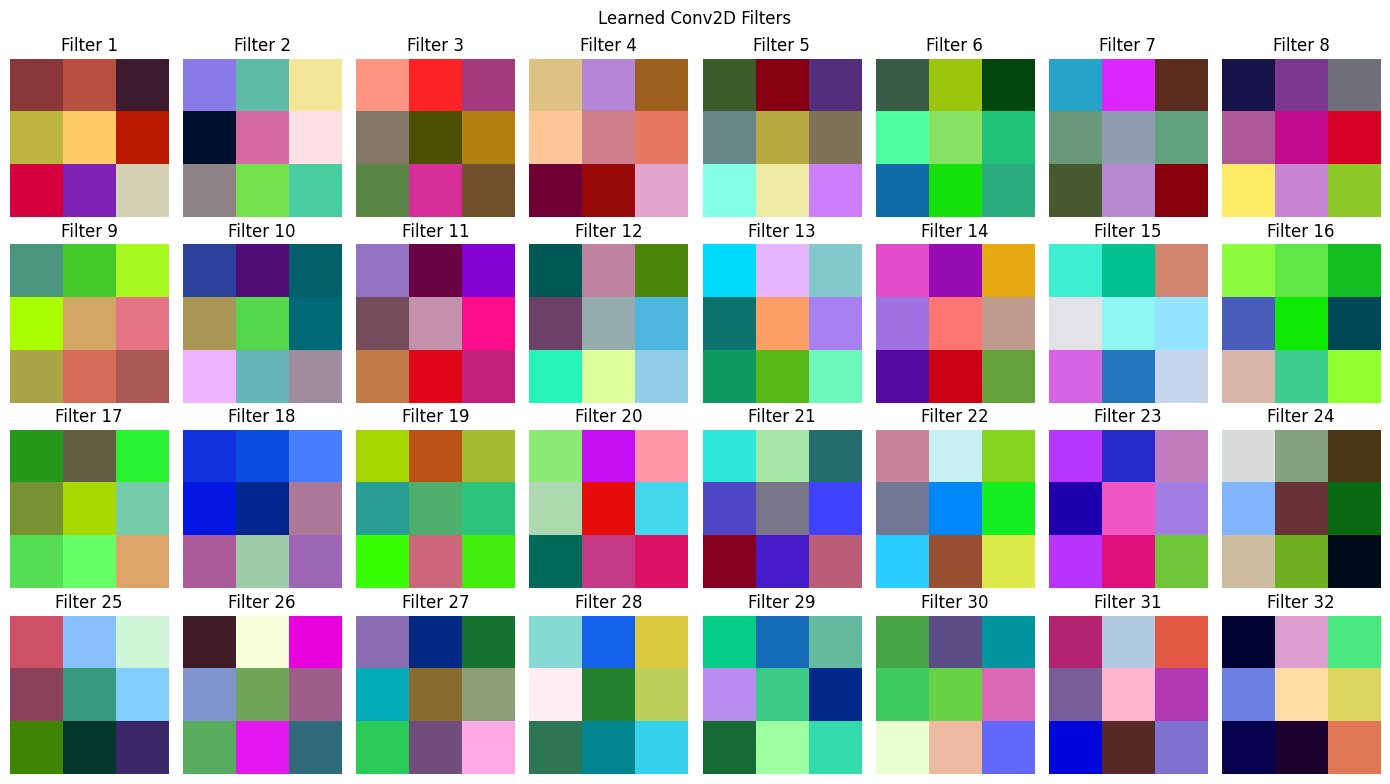

In [38]:
first_conv = next(
    layer for layer in model.layers
    if isinstance(layer, layers.Conv2D)
)
filter_weights, filter_biases = first_conv.get_weights()

print("Filter tensor shape:", filter_weights.shape)
print("Bias vector shape:", filter_biases.shape)

num_filters = min(filter_weights.shape[-1], 32)
cols = 8
rows = int(np.ceil(num_filters / cols))
fig, axes = plt.subplots(rows, cols, figsize=(14, 2 * rows), squeeze=False)

for i, ax in enumerate(axes.flat):
    if i < num_filters:
        kernel = filter_weights[:, :, :, i]

        kernel = (kernel - kernel.min()) / (kernel.max() - kernel.min() + 1e-8)
        ax.imshow(kernel)
        ax.set_title(f"Filter {i + 1}")
    ax.axis("off")

plt.suptitle("Learned Conv2D Filters")
plt.tight_layout()
plt.show()

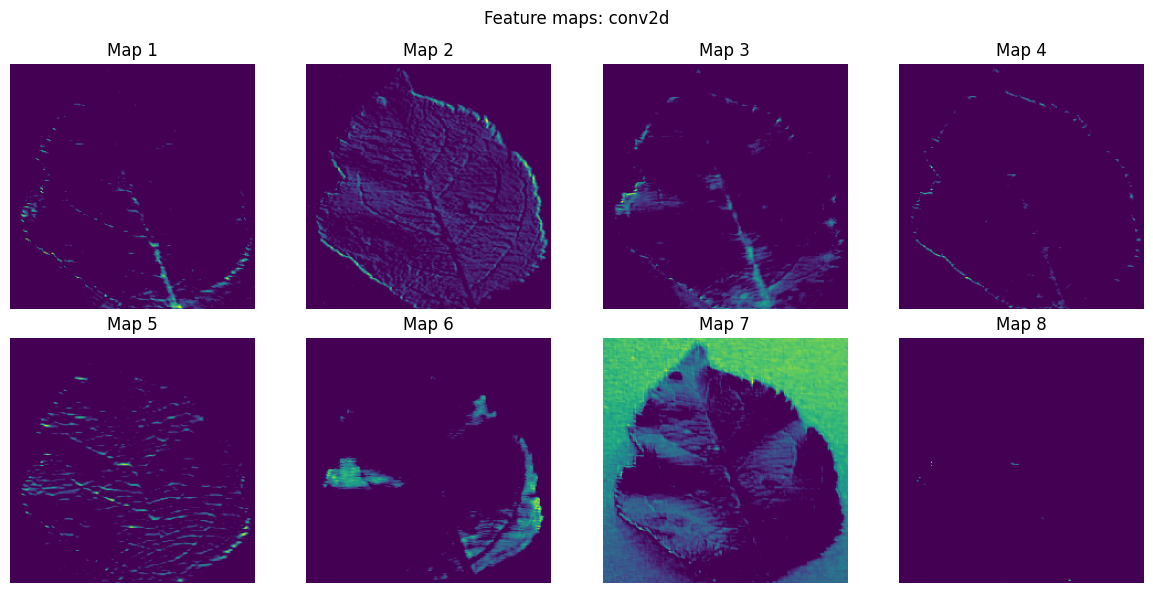

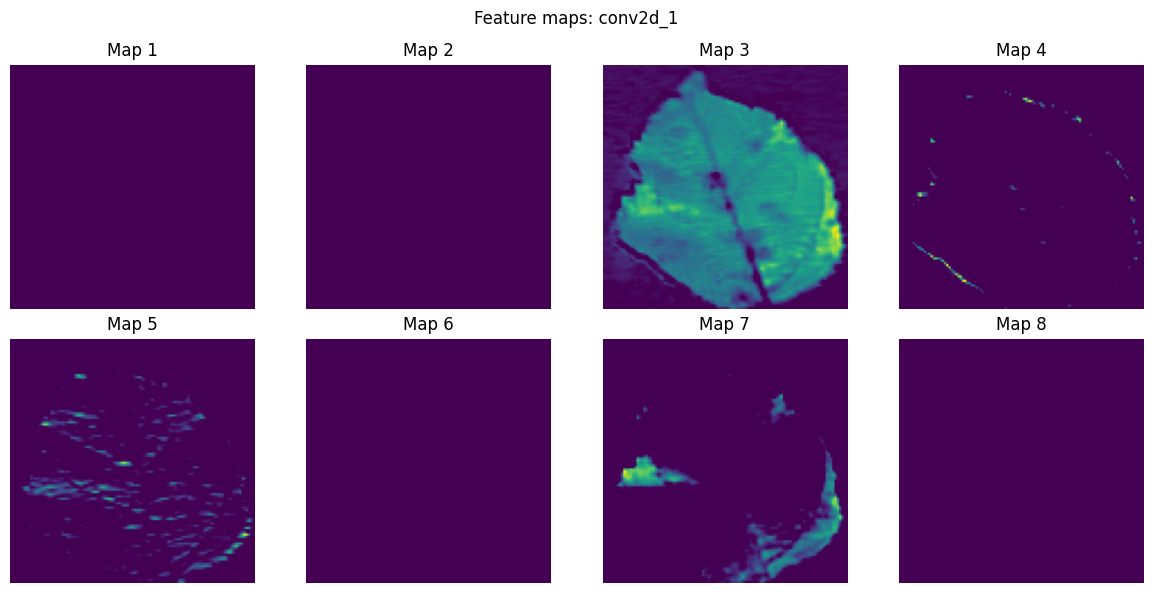

In [39]:
validation_generator.reset()
sample_batch, _ = next(validation_generator)
sample_image = sample_batch[:1]

conv_layers = [
    layer for layer in model.layers
    if isinstance(layer, layers.Conv2D)
]
activation_model = models.Model(
    inputs=model.inputs,
    outputs=[layer.output for layer in conv_layers]
)
activation_maps = activation_model.predict(sample_image, verbose=0)

for layer, activation in zip(conv_layers, activation_maps):
    n_maps = min(8, activation.shape[-1])
    fig, axes = plt.subplots(2, 4, figsize=(12, 6))
    for i, ax in enumerate(axes.flat):
        if i < n_maps:
            ax.imshow(activation[0, :, :, i], cmap="viridis")
            ax.set_title(f"Map {i + 1}")
        ax.axis("off")
    plt.suptitle(f"Feature maps: {layer.name}")
    plt.tight_layout()
    plt.show()


### **Building a Predictive System**

In [40]:
import PIL

def load_and_preprocess_image(image_path, target_size=(224, 224)):
    # Using absolute reference to PIL to avoid IPython.display conflict
    img = PIL.Image.open(image_path)
    img = img.resize(target_size)
    img_array = np.array(img)
    img_array = np.expand_dims(img_array, axis=0)
    img_array = img_array.astype('float32') / 255.
    return img_array

In [41]:
def predict_image_class(model, image_path, class_indices):
    preprocessed_img = load_and_preprocess_image(image_path)
    predictions = model.predict(preprocessed_img)
    predicted_class_index = np.argmax(predictions, axis=1)[0]
    predicted_class_name = class_indices[predicted_class_index]
    return predicted_class_name

In [42]:
class_indices = {v: k for k, v in train_generator.class_indices.items()}

In [43]:
class_indices

{0: 'Apple___Apple_scab',
 1: 'Apple___Black_rot',
 2: 'Apple___Cedar_apple_rust',
 3: 'Apple___healthy',
 4: 'Blueberry___healthy',
 5: 'Cherry_(including_sour)___Powdery_mildew',
 6: 'Cherry_(including_sour)___healthy',
 7: 'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot',
 8: 'Corn_(maize)___Common_rust_',
 9: 'Corn_(maize)___Northern_Leaf_Blight',
 10: 'Corn_(maize)___healthy',
 11: 'Grape___Black_rot',
 12: 'Grape___Esca_(Black_Measles)',
 13: 'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)',
 14: 'Grape___healthy',
 15: 'Orange___Haunglongbing_(Citrus_greening)',
 16: 'Peach___Bacterial_spot',
 17: 'Peach___healthy',
 18: 'Pepper,_bell___Bacterial_spot',
 19: 'Pepper,_bell___healthy',
 20: 'Potato___Early_blight',
 21: 'Potato___Late_blight',
 22: 'Potato___healthy',
 23: 'Raspberry___healthy',
 24: 'Soybean___healthy',
 25: 'Squash___Powdery_mildew',
 26: 'Strawberry___Leaf_scorch',
 27: 'Strawberry___healthy',
 28: 'Tomato___Bacterial_spot',
 29: 'Tomato___Early_blight',
 30: '

In [44]:
import json

json_path = os.path.join(MODEL_DIR, "class_indices.json")

with open(json_path, 'w') as f:
    json.dump(class_indices, f, indent=4)

print("Class indices saved to:", json_path)

Class indices saved to: /content/drive/MyDrive/Colab Notebooks/ML_Projects/Plant_Disease_Detection/class_indices.json


In [47]:
# Example prediction
validation_generator.reset()
sample_batch, _ = next(validation_generator)

example_path = (
    "/content/plantvillage dataset/color/"
    "Tomato___Tomato_Yellow_Leaf_Curl_Virus/"
    "7e25ef0a-7cec-45c2-bc3f-2429b82cafd6___YLCV_GCREC 1896.JPG"
)

predicted_class_name = predict_image_class(model, example_path, class_indices)
print("Example image:", example_path)
print("Predicted class:", predicted_class_name)

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
Example image: /content/plantvillage dataset/color/Tomato___Tomato_Yellow_Leaf_Curl_Virus/7e25ef0a-7cec-45c2-bc3f-2429b82cafd6___YLCV_GCREC 1896.JPG
Predicted class: Tomato___Tomato_Yellow_Leaf_Curl_Virus


### **Save the model to Google drive**

In [49]:
final_model_path = os.path.join(MODEL_DIR, "plant_disease_prediction_model.keras")
model.save(final_model_path)
print("Model saved to:", final_model_path)

Model saved to: /content/drive/MyDrive/Colab Notebooks/ML_Projects/Plant_Disease_Detection/plant_disease_prediction_model.keras
